<a href="https://colab.research.google.com/github/Soumita-Karmakar/Industrial-Machine-Failure-Prediction-/blob/main/Industrial_Machine_Failure_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Understand and load the dataset**

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [63]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [64]:
df = pd.read_csv('/content/drive/MyDrive/Industrial Machine Failure Prediction /dataset/ai4i2020.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [65]:
print("Dataset Shape:", df.shape)

Dataset Shape: (10000, 14)


In [66]:
display(df.head())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [67]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes:

In [68]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [69]:
print("Dataset Statistical Summary:")
display(df.describe())

Dataset Statistical Summary:


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


**2. Perform exploratory data analysis (EDA)**

In [70]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [71]:
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Total Missing Values:
0


In [72]:
print("\nTotal Duplicate Records:")
print(df.duplicated().sum())


Total Duplicate Records:
0


Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


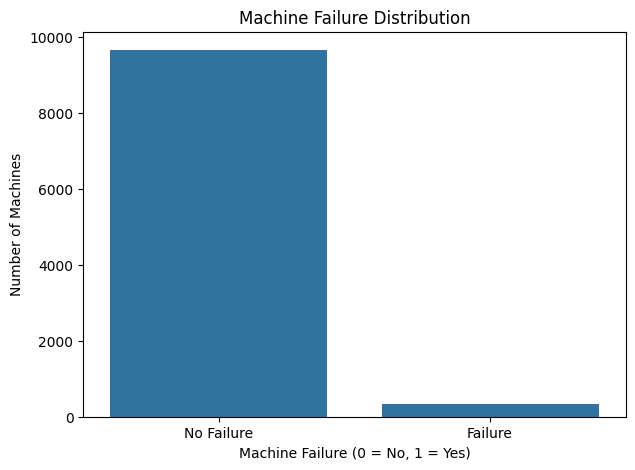

In [73]:
# Count machine failure cases
failure_counts = df["Machine failure"].value_counts()

print("Machine Failure Distribution:")
print(failure_counts)

# Calculate percentages
failure_percentage = df["Machine failure"].value_counts(normalize=True) * 100

print("\nMachine Failure Percentage:")
print(failure_percentage)

# Visualize distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")
plt.xticks([0, 1], ["No Failure", "Failure"])

plt.show()

In [74]:
#Check individual failure type distribution
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("Individual Failure Type Counts:")
display(df[failure_types].sum().sort_values(ascending=False))

Individual Failure Type Counts:


,0
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


In [75]:
#Check whether the failure indicators agree with the target
print("Failure Indicator Consistency:")
print(
    (df[failure_types].sum(axis=1) > 0)
    .eq(df["Machine failure"].eq(1))
    .value_counts()
)

Failure Indicator Consistency:
True     9973
False      27
Name: count, dtype: int64


Machine Type Distribution:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

Machine Type Percentage:
Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64


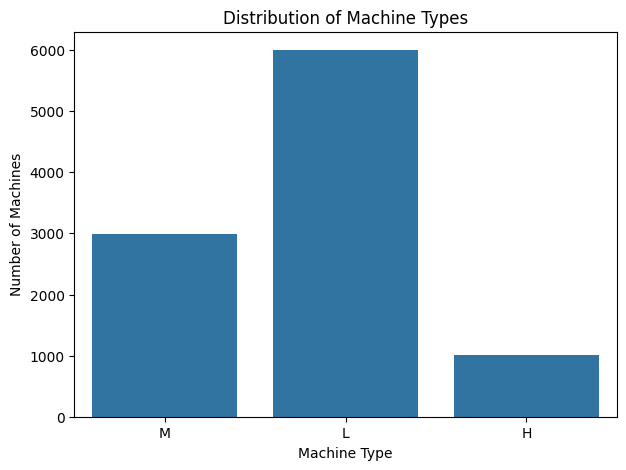

In [76]:
# Analyze machine types
print("Machine Type Distribution:")
print(df["Type"].value_counts())

print("\nMachine Type Percentage:")
print(df["Type"].value_counts(normalize=True) * 100)

# Visualize machine types
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Type")

plt.title("Distribution of Machine Types")
plt.xlabel("Machine Type")
plt.ylabel("Number of Machines")

plt.show()

Machine Failure by Type:


Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83



Failure Percentage by Machine Type:


Machine failure,0,1
Type,,
H,97.906281,2.093719
L,96.083333,3.916667
M,97.230564,2.769436


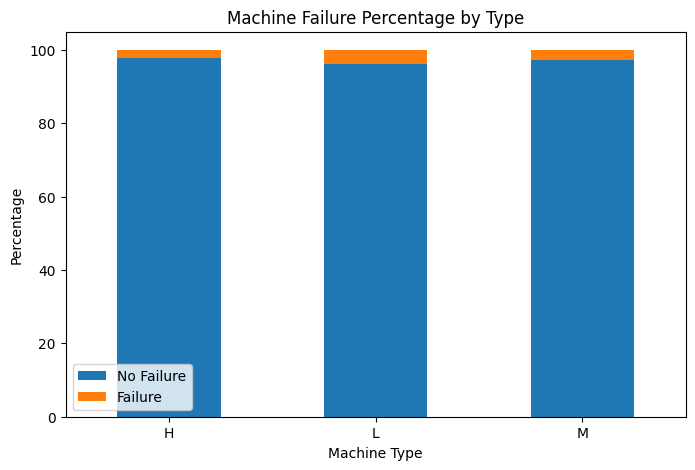

In [77]:
# Count failures by machine type
failure_by_type = pd.crosstab(
    df["Type"],
    df["Machine failure"]
)

print("Machine Failure by Type:")
display(failure_by_type)

# Calculate failure percentages
failure_rate = pd.crosstab(
    df["Type"],
    df["Machine failure"],
    normalize="index"
) * 100

print("\nFailure Percentage by Machine Type:")
display(failure_rate)

# Visualize
failure_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Machine Failure Percentage by Type")
plt.xlabel("Machine Type")
plt.ylabel("Percentage")
plt.legend(["No Failure", "Failure"])
plt.xticks(rotation=0)
plt.show()

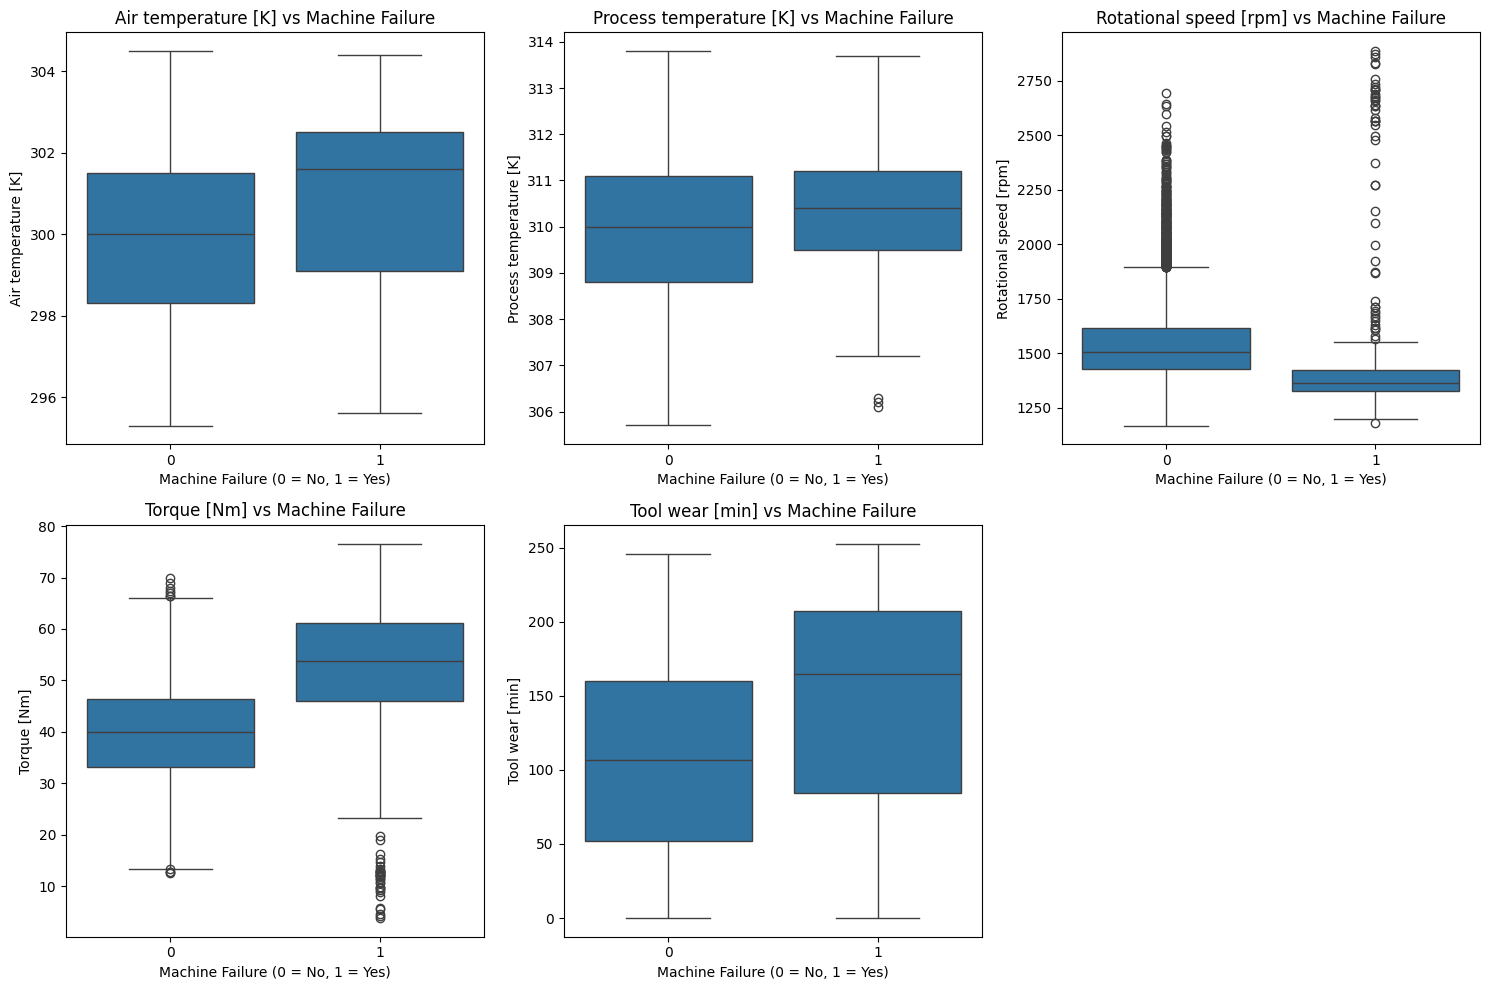

In [78]:
# Select numerical features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Compare feature distributions by failure status
plt.figure(figsize=(15, 10))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature
    )

    plt.title(f"{feature} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

Correlation with Machine Failure:
Machine failure            1.000000
Torque [Nm]                0.191321
Tool wear [min]            0.105448
Air temperature [K]        0.082556
Process temperature [K]    0.035946
Rotational speed [rpm]    -0.044188
Name: Machine failure, dtype: float64


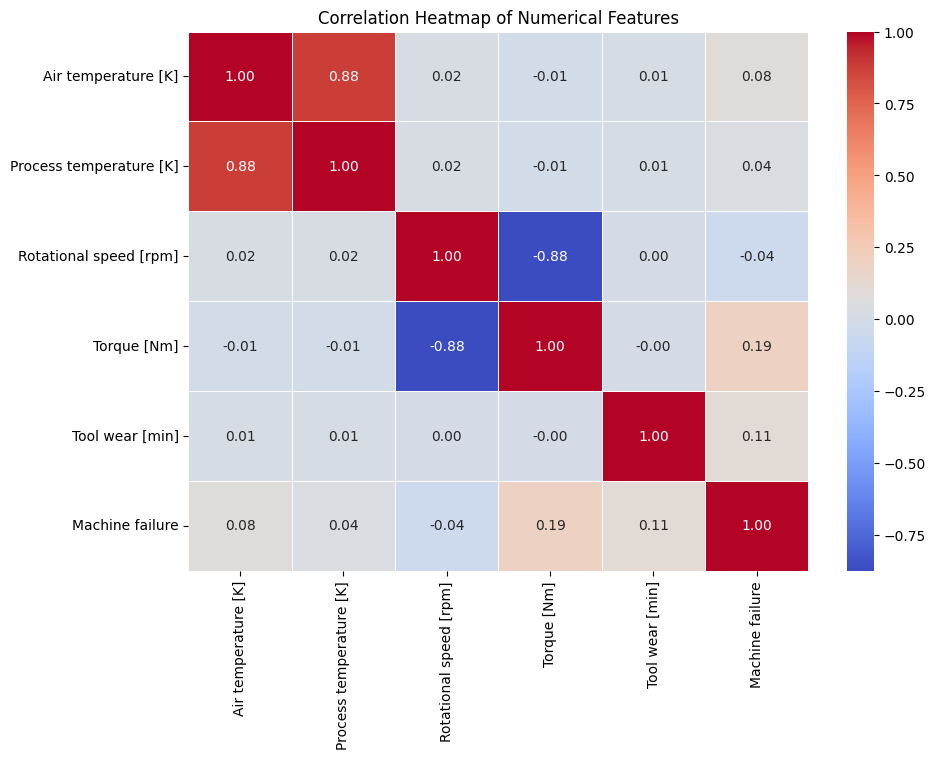

In [79]:
# Select numerical features and target
correlation_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

# Calculate correlation matrix
correlation_matrix = df[correlation_features].corr()

print("Correlation with Machine Failure:")
print(
    correlation_matrix["Machine failure"]
    .sort_values(ascending=False)
)

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**3. Prepare the data**

In [80]:
# Create a copy of the dataset
data = df.copy()

# Remove unnecessary and data leakage columns
columns_to_drop = [
    "UDI",
    "Product ID",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

data = data.drop(columns=columns_to_drop)

# Display the updated dataset
print("Dataset after removing unnecessary columns:")
print(data.head())

print("\nUpdated Dataset Shape:", data.shape)

print("\nRemaining Columns:")
print(data.columns.tolist())

Dataset after removing unnecessary columns:
  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   
1    L                298.2                    308.7                    1408   
2    L                298.1                    308.5                    1498   
3    L                298.2                    308.6                    1433   
4    L                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Machine failure  
0         42.8                0                0  
1         46.3                3                0  
2         49.4                5                0  
3         39.5                7                0  
4         40.0                9                0  

Updated Dataset Shape: (10000, 7)

Remaining Columns:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [mi

In [81]:
# Check data quality
print("Missing Values:", data.isnull().sum().sum())
print("Duplicate Records:", data.duplicated().sum())
print("Infinite Values:", np.isinf(
    data.select_dtypes(include=np.number)
).sum().sum())

Missing Values: 0
Duplicate Records: 0
Infinite Values: 0


In [82]:
# Apply One-Hot Encoding to the Type column
data = pd.get_dummies(
    data,
    columns=["Type"],
    dtype=int
)

# Display the encoded dataset
print("Dataset after One-Hot Encoding:")
display(data.head())

print("\nUpdated Dataset Shape:", data.shape)

print("\nRemaining Columns:")
print(data.columns.tolist())

Dataset after One-Hot Encoding:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,0,1,0
2,298.1,308.5,1498,49.4,5,0,0,1,0
3,298.2,308.6,1433,39.5,7,0,0,1,0
4,298.2,308.7,1408,40.0,9,0,0,1,0



Updated Dataset Shape: (10000, 9)

Remaining Columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'Type_H', 'Type_L', 'Type_M']


In [83]:
# Separate input features and target variable

X = data.drop("Machine failure", axis=1)
y = data["Machine failure"]

print("Input Features (X):", X.shape)
print("Target Variable (y):", y.shape)

print("\nInput Feature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Input Features (X): (10000, 8)
Target Variable (y): (10000,)

Input Feature Columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']

Target Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [84]:
# Verify input features
print("Data Types of Input Features:")
print(X.dtypes)

print("\nMissing Values in X:", X.isnull().sum().sum())

print("Infinite Values in X:",
      np.isinf(X.select_dtypes(include=np.number)).sum().sum())

print("\nMissing Values in y:", y.isnull().sum())

print("\nFinal Input Shape:", X.shape)
print("Final Target Shape:", y.shape)

Data Types of Input Features:
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Type_H                       int64
Type_L                       int64
Type_M                       int64
dtype: object

Missing Values in X: 0
Infinite Values in X: 0

Missing Values in y: 0

Final Input Shape: (10000, 8)
Final Target Shape: (10000,)


**4. Split the dataset**

In [85]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Check class distribution in training data
print("\nTraining Class Distribution:")
print(y_train.value_counts())

# Check class distribution in testing data
print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (8000, 8)
Testing Features: (2000, 8)

Training Target: (8000,)
Testing Target: (2000,)

Training Class Distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing Class Distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [86]:

from sklearn.preprocessing import StandardScaler

# Select numerical sensor features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Create copies of training and testing datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Create StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform it
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform testing data using the same scaler
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

# Display scaled datasets
print("Training Data after Scaling:")
display(X_train_scaled.head())

print("\nTesting Data after Scaling:")
display(X_test_scaled.head())

# Display dataset shapes
print("\nTraining Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)


Training Data after Scaling:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0,0,1
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0,0,1
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0,0,1
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0,1,0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0,1,0



Testing Data after Scaling:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
2997,0.247681,-0.139294,-1.073963,2.265378,0.712410,0,1,0
4871,1.850310,1.618248,-0.145641,0.009646,0.429427,0,1,0
3858,1.249324,0.942270,0.108543,-0.239882,1.592802,0,1,0
951,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,1,0,0
6463,0.247681,-0.004098,-1.002129,2.035812,-0.089376,1,0,0



Training Shape: (8000, 8)
Testing Shape: (2000, 8)


In [87]:
from sklearn.preprocessing import StandardScaler

# Select numerical sensor features
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Create a copy of training and testing datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Create StandardScaler
scaler = StandardScaler()

# Fit scaler on training data and transform it
X_train_scaled[numerical_features] = scaler.fit_transform(
    X_train[numerical_features]
)

# Transform testing data using the same scaler
X_test_scaled[numerical_features] = scaler.transform(
    X_test[numerical_features]
)

# Display results
print("Training Data after Scaling:")
display(X_train_scaled.head())

print("\nTesting Data after Scaling:")
display(X_test_scaled.head())

print("\nTraining Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Training Data after Scaling:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
4058,0.998914,0.604282,-0.460607,0.718305,-0.843997,0,0,1
1221,-1.505194,-1.153260,-0.775574,0.638456,0.382263,0,0,1
6895,0.498092,1.077466,-1.007654,0.558607,0.460870,0,0,1
9863,-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0,1,0
8711,-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0,1,0



Testing Data after Scaling:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
2997,0.247681,-0.139294,-1.073963,2.265378,0.712410,0,1,0
4871,1.850310,1.618248,-0.145641,0.009646,0.429427,0,1,0
3858,1.249324,0.942270,0.108543,-0.239882,1.592802,0,1,0
951,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,1,0,0
6463,0.247681,-0.004098,-1.002129,2.035812,-0.089376,1,0,0



Training Shape: (8000, 8)
Testing Shape: (2000, 8)


**5. Train three classification models**

**MODEL-1 •	Logistic Regression**

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Logistic Regression model
lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Predict on testing data
y_pred_lr = lr_model.predict(X_test_scaled)

# Evaluate the model
print("Logistic Regression Results")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Results
--------------------------------
Accuracy: 0.8245

Confusion Matrix:
[[1593  339]
 [  12   56]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



**Decision Tree Classifier**

In [89]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

# Train the model
dt_model.fit(X_train, y_train)

# Predict on testing data
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
print("Decision Tree Results")
print("-----------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Results
-----------------------------
Accuracy: 0.978

Confusion Matrix:
[[1915   17]
 [  27   41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.60      0.65        68

    accuracy                           0.98      2000
   macro avg       0.85      0.80      0.82      2000
weighted avg       0.98      0.98      0.98      2000



**Random Forest Classifier**

In [90]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on testing data
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
print("Random Forest Results")
print("-----------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
-----------------------------
Accuracy: 0.979

Confusion Matrix:
[[1931    1]
 [  41   27]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.96      0.40      0.56        68

    accuracy                           0.98      2000
   macro avg       0.97      0.70      0.78      2000
weighted avg       0.98      0.98      0.97      2000



**6. Evaluate and compare the models**

In [91]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

print("Model Performance Comparison:")
display(model_comparison.round(4))


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419
1,Decision Tree,0.9780,0.7069,0.6029,0.6508
2,Random Forest,0.9790,0.9643,0.3971,0.5625


**7. Perform cross-validation**

In [92]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


In [93]:

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

print("All three models are ready for cross-validation.")


All three models are ready for cross-validation.


In [94]:

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Perform cross-validation for each model
cv_results = {}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results[name] = {
        "Accuracy Scores": scores["test_accuracy"],
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Precision Scores": scores["test_precision"],
        "Mean Precision": scores["test_precision"].mean(),
        "Recall Scores": scores["test_recall"],
        "Mean Recall": scores["test_recall"].mean(),
        "F1 Scores": scores["test_f1"],
        "Mean F1 Score": scores["test_f1"].mean()
    }

    print("\n==========", name, "==========")
    print("Accuracy Scores:", scores["test_accuracy"])
    print("Average Accuracy:", round(scores["test_accuracy"].mean(), 4))

    print("Precision Scores:", scores["test_precision"])
    print("Average Precision:", round(scores["test_precision"].mean(), 4))

    print("Recall Scores:", scores["test_recall"])
    print("Average Recall:", round(scores["test_recall"].mean(), 4))

    print("F1 Scores:", scores["test_f1"])
    print("Average F1 Score:", round(scores["test_f1"].mean(), 4))



========== Logistic Regression ==========
Accuracy Scores: [0.816875 0.835625 0.8175   0.825625 0.816875]
Average Accuracy: 0.8225
Precision Scores: [0.14328358 0.13074205 0.13496933 0.14285714 0.13496933]
Average Precision: 0.1374
Recall Scores: [0.88888889 0.68518519 0.81481481 0.83333333 0.8       ]
Average Recall: 0.8044
F1 Scores: [0.24678663 0.21958457 0.23157895 0.24390244 0.23097113]
Average F1 Score: 0.2346

========== Decision Tree ==========
Accuracy Scores: [0.9775   0.974375 0.978125 0.974375 0.9775  ]
Average Accuracy: 0.9764
Precision Scores: [0.68       0.68571429 0.72093023 0.61818182 0.74358974]
Average Precision: 0.6897
Recall Scores: [0.62962963 0.44444444 0.57407407 0.62962963 0.52727273]
Average Recall: 0.561
F1 Scores: [0.65384615 0.53932584 0.63917526 0.62385321 0.61702128]
Average F1 Score: 0.6146

========== Random Forest ==========
Accuracy Scores: [0.980625 0.976875 0.9775   0.97625  0.974375]
Average Accuracy: 0.9771
Precision Scores: [1.         0.9047619

In [95]:

# Create cross-validation comparison table
cv_comparison = pd.DataFrame({
    "Model": list(cv_results.keys()),
    "Average Accuracy": [
        cv_results[m]["Mean Accuracy"] for m in models
    ],
    "Average Precision": [
        cv_results[m]["Mean Precision"] for m in models
    ],
    "Average Recall": [
        cv_results[m]["Mean Recall"] for m in models
    ],
    "Average F1 Score": [
        cv_results[m]["Mean F1 Score"] for m in models
    ]
})

print("Cross-Validation Model Comparison:")
display(cv_comparison.round(4))


Cross-Validation Model Comparison:


,Model,Average Accuracy,Average Precision,Average Recall,Average F1 Score
0,Logistic Regression,0.8225,0.1374,0.8044,0.2346
1,Decision Tree,0.9764,0.6897,0.5610,0.6146
2,Random Forest,0.9771,0.8994,0.3655,0.5193


**8. Perform hyperparameter tuning**

In [96]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully.")


GridSearchCV imported successfully.


In [97]:

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        random_state=42,
        max_iter=1000,
        class_weight="balanced"
    ))
])

lr_params = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Logistic Regression Best Parameters:")
print(lr_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(lr_grid.best_score_)


Logistic Regression Best Parameters:
{'model__C': 1}
Best Cross-Validation F1 Score:
0.23456474342508365


In [98]:

dt_params = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_grid=dt_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Decision Tree Best Parameters:")
print(dt_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(dt_grid.best_score_)


Decision Tree Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best Cross-Validation F1 Score:
0.6394747349765275


In [99]:

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    param_grid=rf_params,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Random Forest Best Parameters:")
print(rf_grid.best_params_)

print("Best Cross-Validation F1 Score:")
print(rf_grid.best_score_)

Random Forest Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation F1 Score:
0.6418629671933144


**9. Select the best model**

In [100]:

# Compare tuned models

tuned_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Best CV F1 Score": [
        lr_grid.best_score_,
        dt_grid.best_score_,
        rf_grid.best_score_
    ]
})

print("Tuned Model Comparison:")
display(tuned_comparison.sort_values(
    by="Best CV F1 Score",
    ascending=False
))

# Select the best model
best_model_name = tuned_comparison.loc[
    tuned_comparison["Best CV F1 Score"].idxmax(),
    "Model"
]

best_model = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_
}[best_model_name]

print("\nSelected Best Model:", best_model_name)


Tuned Model Comparison:


,Model,Best CV F1 Score
2,Random Forest,0.641863
1,Decision Tree,0.639475
0,Logistic Regression,0.234565



Selected Best Model: Random Forest


In [101]:
final_model = best_model

print("Final Selected Model:", best_model_name)

Final Selected Model: Random Forest


Selected Model: Random Forest

Final Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.82      0.62      0.71        68

    accuracy                           0.98      2000
   macro avg       0.91      0.81      0.85      2000
weighted avg       0.98      0.98      0.98      2000


Final Confusion Matrix:
[[1923    9]
 [  26   42]]


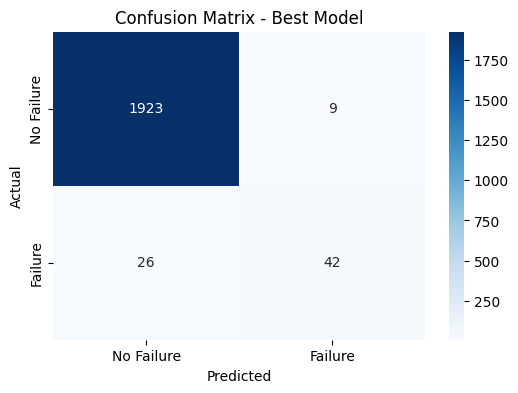

In [102]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict using the selected model
y_pred_best = best_model.predict(X_test)

# Display classification report
print("Selected Model:", best_model_name)

print("\nFinal Classification Report:")
print(classification_report(y_test, y_pred_best))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

print("\nFinal Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - Best Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**10. Predict new, unseen machine data**

In [103]:
# New machine sensor data

new_machine = pd.DataFrame([{
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 45.0,
    "Tool wear [min]": 120,
    "Type_H": 0,
    "Type_L": 0,
    "Type_M": 1
}])

# Keep the same feature order used during training
new_machine = new_machine.reindex(columns=X_train.columns)

# Predict machine failure
prediction = best_model.predict(new_machine)[0]

# Calculate failure probability
failure_probability = best_model.predict_proba(new_machine)[0][1]

print("Machine Failure Prediction")
print("--------------------------")

if prediction == 1:
    print("Prediction: Machine Failure: YES")
else:
    print("Prediction: Machine Failure: NO")

print("Estimated Failure Probability:",
      round(failure_probability * 100, 2), "%")

Machine Failure Prediction
--------------------------
Prediction: Machine Failure: NO
Estimated Failure Probability: 0.0 %


**11. Save the model and prepare the final demonstration**

In [104]:
import joblib

# Save the selected model and feature names
model_data = {
    "model": best_model,
    "feature_columns": list(X_train.columns)
}

joblib.dump(model_data, "machine_failure_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [105]:
# Load saved model
loaded_data = joblib.load("machine_failure_model.pkl")

loaded_model = loaded_data["model"]
feature_columns = loaded_data["feature_columns"]

print("Model loaded successfully!")
print("Model:", type(loaded_model).__name__)
print("Features:", feature_columns)

Model loaded successfully!
Model: RandomForestClassifier
Features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


In [107]:

# Machine Failure Prediction System

# Take machine sensor values from the user
print("===== MACHINE FAILURE PREDICTION SYSTEM =====")

air_temp = float(input("Enter Air Temperature [K]: "))
process_temp = float(input("Enter Process Temperature [K]: "))
rotational_speed = float(input("Enter Rotational Speed [rpm]: "))
torque = float(input("Enter Torque [Nm]: "))
tool_wear = float(input("Enter Tool Wear [min]: "))

machine_type = input("Enter Machine Type (L, M, H): ").strip().upper()

# Validate machine type
if machine_type not in ["L", "M", "H"]:
    print("Invalid machine type! Enter L, M, or H.")

else:
    # Create new machine data
    new_machine = pd.DataFrame([{
        "Air temperature [K]": air_temp,
        "Process temperature [K]": process_temp,
        "Rotational speed [rpm]": rotational_speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear,
        "Type_H": int(machine_type == "H"),
        "Type_L": int(machine_type == "L"),
        "Type_M": int(machine_type == "M")
    }])

    # Maintain the same feature order used during training
    new_machine = new_machine.reindex(columns=feature_columns)

    # Predict using saved model
    prediction = loaded_model.predict(new_machine)[0]

    # Calculate failure probability
    probability = loaded_model.predict_proba(new_machine)[0][1]

    # Display prediction
    print("\n===== MACHINE FAILURE PREDICTION =====")

    if prediction == 1:
        print("Result: MACHINE FAILURE - YES")
    else:
        print("Result: MACHINE FAILURE - NO")

    print("Estimated Failure Probability:",
          round(probability * 100, 2), "%")

===== MACHINE FAILURE PREDICTION SYSTEM =====
Enter Air Temperature [K]: 300
Enter Process Temperature [K]: 310
Enter Rotational Speed [rpm]: 1500
Enter Torque [Nm]: 45
Enter Tool Wear [min]: 120
Enter Machine Type (L, M, H): L

===== MACHINE FAILURE PREDICTION =====
Result: MACHINE FAILURE - NO
Estimated Failure Probability: 0.0 %
